In [193]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [194]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/home_prices.csv")
data.head()

,area_sqr_ft,bedrooms,color,price_lakhs
0,3774,2,Red,216
1,1460,3,Gray,88
2,1894,4,Gray,147
3,1730,2,Blue,84
4,1695,1,Blue,77


In [195]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   area_sqr_ft  300 non-null    int64
 1   bedrooms     300 non-null    int64
 2   color        300 non-null    str  
 3   price_lakhs  300 non-null    int64
dtypes: int64(3), str(1)
memory usage: 9.5 KB


In [196]:
data.describe()

,area_sqr_ft,bedrooms,price_lakhs
count,300.000000,300.000000,300.000000
mean,2371.990000,3.013333,148.050000
std,942.766953,1.446882,52.873113
min,601.000000,1.000000,15.000000
25%,1620.750000,2.000000,107.750000
50%,2342.500000,3.000000,151.000000
75%,3206.000000,4.000000,191.000000
max,3997.000000,5.000000,250.000000


In [197]:
data.isnull().sum()

area_sqr_ft    0
bedrooms       0
color          0
price_lakhs    0
dtype: int64

In [198]:
data.duplicated().sum()

np.int64(0)

In [199]:
data = pd.get_dummies(data, dtype=int)
data.head()

,area_sqr_ft,bedrooms,price_lakhs,color_Blue,color_Gray,color_Green,color_Red,color_White,color_Yellow
0,3774,2,216,0,0,0,1,0,0
1,1460,3,88,0,1,0,0,0,0
2,1894,4,147,0,1,0,0,0,0
3,1730,2,84,1,0,0,0,0,0
4,1695,1,77,1,0,0,0,0,0


<Axes: >

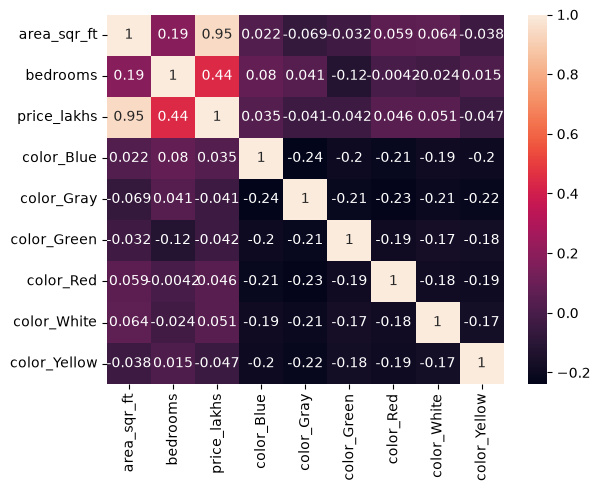

In [200]:
sns.heatmap(data.corr(), annot=True)

In [201]:
#Color not able to predict price(corr comes between -0.3 to +0.3),so remove colors

In [202]:
df = data.drop(['color_Blue','color_Gray','color_Green','color_Red','color_White','color_Yellow'], axis=1)
df.head()

,area_sqr_ft,bedrooms,price_lakhs
0,3774,2,216
1,1460,3,88
2,1894,4,147
3,1730,2,84
4,1695,1,77


In [203]:
X = df.iloc[:,:1]
y = df.iloc[:,-1]

In [204]:
from sklearn.model_selection import train_test_split

In [205]:
X_train,X_test,y_train,y_test = train_test_split(X,y, random_state = 280,test_size=0.2)

In [206]:
X_train.shape

(240, 1)

In [207]:
X_test.shape

(60, 1)

In [208]:
y_train.shape

(240,)

In [209]:
y_test.shape

(60,)

In [210]:
from sklearn.linear_model import LinearRegression

In [211]:
model = LinearRegression()

In [212]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area_sqr_ft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [213]:
train_pred = model.predict(X_train)

In [214]:
from sklearn.metrics import r2_score

In [215]:
r2_score(y_train, train_pred)

0.8871779171015823

In [216]:
test_pred = model.predict(X_test)

In [217]:
r2_score(y_test, test_pred)

0.9155340636049708

### Calculate VIF

In [218]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/salaries for VIF.csv")
data.head()

,Years of Experience,Education Level,Age,Location Factor,Salary
0,29,1,49,7,124204
1,27,3,45,4,125948
2,20,4,41,8,116078
3,14,4,37,5,106486
4,20,3,42,7,113297


In [219]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Years of Experience  1000 non-null   int64
 1   Education Level      1000 non-null   int64
 2   Age                  1000 non-null   int64
 3   Location Factor      1000 non-null   int64
 4   Salary               1000 non-null   int64
dtypes: int64(5)
memory usage: 39.2 KB


In [220]:
data.describe()

,Years of Experience,Education Level,Age,Location Factor,Salary
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,19.416000,2.449000,39.725000,5.448000,109207.756000
std,10.689397,1.118324,10.494928,2.912005,23121.103747
min,-11.000000,1.000000,6.000000,1.000000,43329.000000
25%,12.000000,1.000000,33.000000,3.000000,93877.750000
50%,19.000000,2.000000,40.000000,5.000000,108414.000000
75%,27.000000,3.000000,47.000000,8.000000,124592.750000
max,51.000000,4.000000,72.000000,10.000000,175798.000000


In [221]:
data.isnull().sum()

Years of Experience    0
Education Level        0
Age                    0
Location Factor        0
Salary                 0
dtype: int64

In [222]:
data.duplicated().sum()

np.int64(0)

<Axes: >

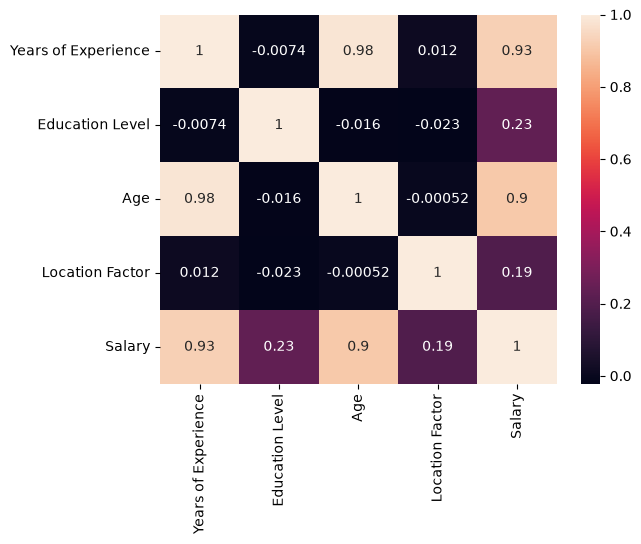

In [223]:
sns.heatmap(data.corr(), annot=True)

In [224]:
#Location factor and Education Level not able to predict salary(corr comes between -0.3 to +0.3),so remove Location factor and Education Level
# Years of Experience and age shows strong corr between them,ind and ind strong so remove Age

In [225]:
df = data.drop(['Education Level','Age','Location Factor'], axis=1)
df.head()

,Years of Experience,Salary
0,29,124204
1,27,125948
2,20,116078
3,14,106486
4,20,113297


In [226]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [227]:
from sklearn.model_selection import train_test_split

In [228]:
X_train,X_test,y_train,y_test = train_test_split(X,y, random_state = 3 ,test_size=0.2)

In [229]:
X_test.shape

(200, 1)

In [230]:
X_train.shape

(800, 1)

In [231]:
y_test.shape

(200,)

In [232]:
y_train.shape

(800,)

In [233]:
from sklearn.linear_model import LinearRegression

In [234]:
model = LinearRegression()

In [235]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2001.63]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Years of Experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.039e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [236]:
train_pred = model.predict(X_train)

In [237]:
from sklearn.metrics import r2_score

In [238]:
r2_score(y_train,train_pred)

0.8656347307652802

In [239]:
test_pred = model.predict(X_test)

In [240]:
r2_score(y_test,test_pred)

0.8436252798284133

In [241]:
data.head()

,Years of Experience,Education Level,Age,Location Factor,Salary
0,29,1,49,7,124204
1,27,3,45,4,125948
2,20,4,41,8,116078
3,14,4,37,5,106486
4,20,3,42,7,113297


In [242]:
data1 = data.drop(['Salary'], axis=1)

In [243]:
data1.head()

,Years of Experience,Education Level,Age,Location Factor
0,29,1,49,7
1,27,3,45,4
2,20,4,41,8
3,14,4,37,5
4,20,3,42,7


In [244]:
data1.columns

Index(['Years of Experience', 'Education Level', 'Age', 'Location Factor'], dtype='str')

In [245]:
data1.shape[1]

4

In [246]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
variance_inflation_factor(data1,0)

np.float64(27.789896607809407)

In [247]:
def calculateVIF(df):
    columns = df.columns
    res = pd.DataFrame({'Column Name': columns})
    val =[]
    for i in range(df.shape[1]):
        vif = variance_inflation_factor(df, i)
        val.append(vif)
    res['VIFs'] = val
    return res

In [248]:
calculateVIF(data1)

,Column Name,VIFs
0,Years of Experience,27.789897
1,Education Level,1.002909
2,Age,27.791848
3,Location Factor,1.004877
